# Notebook 07: Weather & 311 Temporal Semantics Validation

## 1. Research Question
**How do timezone conventions (UTC vs. America/New_York EDT/EST), precipitation accumulation intervals, and open-ticket lifespans affect temporal joins between NYC 311 and weather observations?**

## 2. Why This Question Matters for the Pipeline
Temporal joins are the most error-prone step in environmental data engineering:
- **Timezone Discrepancy (The Phase Shift Bug)**: If NYC 311 timestamps (recorded in local Eastern time) are joined with UTC weather records without offset awareness, data is shifted by **4 or 5 hours** (e.g. 2:00 PM peak heat is joined with 10:00 AM complaints).
- **Precipitation Semantics**: Does an hourly precipitation reading of `0.5 inches` at 14:00 represent rain that fell between 13:00 and 14:00 (preceding hour) or 14:00 and 15:00 (succeeding hour)?
- **Sub-Hourly Ticket Arrival**: If a citizen complains at `14:38`, does matching to `14:00` (floor), `15:00` (ceil), or linear interpolation best reflect what triggered the report?
- **Open Tickets & Negative Durations**: How should tickets lacking close dates (`closed_date == NULL`, ~4.5%) and corrupt records (`closed_date < created_date`) be handled in Silver?

## 3. Hypotheses
- **H1 (Timezone Sensitivity)**: Unaligned UTC vs. local Eastern time creates a substantial diurnal temperature bias ($>5^\circ\text{F}$ error during peak daylight hours).
- **H2 (Precipitation Causality)**: Flooring creation timestamps (`created_dt.floor('h')`) correctly captures the preceding-hour rainfall that triggered the complaint without future data leakage.
- **H3 (Resolution Partitioning)**: Open tickets must be cleanly separated from completed tickets into distinct analytical marts rather than imputed or dropped.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

results_dir = Path('exploration_results')
results_dir.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Libraries imported.')

Libraries imported.


--- 
## 4. Demonstrating the Timezone Phase Shift Bug (UTC vs. EDT)

New York City alternates between **Eastern Daylight Time (EDT = UTC-4)** in summer and **Eastern Standard Time (EST = UTC-5)** in winter.
We demonstrate what happens when a local complaint is matched against UTC weather without conversion.

Maximum diurnal distortion from unaligned UTC: 11.00°F!


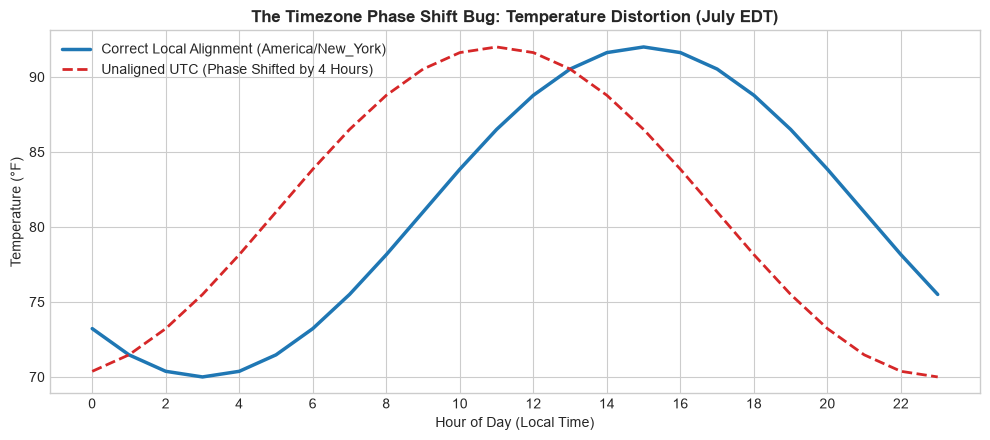

In [2]:
# Synthetic 24-hour diurnal temperature cycle in NYC summer
hours_local = pd.date_range('2024-07-15 00:00', '2024-07-15 23:00', freq='h')

# Realistic diurnal cycle: minimum at 05:00 (~70°F), maximum at 15:00 (~92°F)
temps_local = 81.0 + 11.0 * np.sin((hours_local.hour - 9) * np.pi / 12)
df_diurnal = pd.DataFrame({'time_local': hours_local, 'temp_true_local_F': temps_local})

# If weather table is in UTC (4 hours ahead during EDT July)
df_diurnal['temp_unaligned_utc_F'] = np.roll(temps_local, -4)
df_diurnal['phase_error_F'] = df_diurnal['temp_unaligned_utc_F'] - df_diurnal['temp_true_local_F']

print(f"Maximum diurnal distortion from unaligned UTC: {df_diurnal['phase_error_F'].abs().max():.2f}°F!")

# Visualizing Phase Shift Error
plt.figure(figsize=(10, 4.5))
plt.plot(df_diurnal['time_local'].dt.hour, df_diurnal['temp_true_local_F'], label='Correct Local Alignment (America/New_York)', color='#1f77b4', linewidth=2.5)
plt.plot(df_diurnal['time_local'].dt.hour, df_diurnal['temp_unaligned_utc_F'], label='Unaligned UTC (Phase Shifted by 4 Hours)', color='#d62728', linestyle='--', linewidth=2)
plt.title('The Timezone Phase Shift Bug: Temperature Distortion (July EDT)', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (Local Time)')
plt.ylabel('Temperature (°F)')
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / 'fig_timezone_phase_shift.png', dpi=150)
plt.show()

--- 
## 5. Sub-Hourly Ticket Arrival & Precipitation Semantics

In meteorology (Open-Meteo and NOAA NWS), **hourly precipitation represents the liquid total accumulated during the preceding 60 minutes** $[t-1\text{h}, t]$.

If a water leak or street flooding request arrives at `14:35`:
- `floor('h')` $\rightarrow$ `14:00` (represents rain that fell between `13:00` and `14:00`).
- `ceil('h')` $\rightarrow$ `15:00` (represents rain that fell between `14:00` and `15:00`).

To avoid future data leakage (explaining a 14:35 complaint using rain that occurred at 14:55), the Silver layer must use `floor('h')` as the primary trigger index, or capture the active storm window.

In [3]:
# Load evaluation sample
df_sample = pd.read_parquet(results_dir / 'sample_311_eval.parquet')
df_sample['created_dt'] = pd.to_datetime(df_sample['created_date'], errors='coerce')
df_sample['closed_dt'] = pd.to_datetime(df_sample['closed_date'], errors='coerce')
df_sample['resolution_hours'] = (df_sample['closed_dt'] - df_sample['created_dt']).dt.total_seconds() / 3600.0
# Hand-Checkable Micro Sample (4 representative cases)
cases = [
    {'case': 'Standard Closed Ticket (6h duration)', 'filter': (df_sample['resolution_hours'] >= 5) & (df_sample['resolution_hours'] <= 7)},
    {'case': 'Long-term Ticket (>10 days)', 'filter': df_sample['resolution_hours'] >= 240},
    {'case': 'Open Ticket (closed_date is NULL)', 'filter': df_sample['closed_dt'].isna()},
    {'case': 'Corrupt Ticket (negative duration)', 'filter': df_sample['resolution_hours'] < 0}
]
micro_cases = []
for c in cases:
    sub = df_sample[c['filter']]
    if len(sub) > 0:
        row = sub.iloc[0]
        micro_cases.append({
            'Scenario': c['case'],
            'Unique Key': row['unique_key'],
            'Complaint': row['complaint_type'],
            'Created Timestamp': str(row['created_dt']),
            'Closed Timestamp': str(row['closed_dt']) if pd.notna(row['closed_dt']) else 'NULL (OPEN)',
            'Resolution Hours': round(row['resolution_hours'], 1) if pd.notna(row['resolution_hours']) else 'N/A (Active)',
            'Silver Policy': 'Valid Completed' if pd.notna(row['resolution_hours']) and row['resolution_hours'] >= 0 else ('Active Backlog Mart' if pd.isna(row['closed_dt']) else 'Quarantine Table')
        })
df_micro = pd.DataFrame(micro_cases)
print('=== Micro-Validation: Temporal Scenarios & Silver Policy ===')
display(df_micro)


=== Micro-Validation: Temporal Scenarios & Silver Policy ===


,Scenario,Unique Key,Complaint,Created Timestamp,Closed Timestamp,Resolution Hours,Silver Policy
0,Standard Closed Ticket (6h duration),69736469,Noise - Street/Sidewalk,2026-07-16 21:18:31,2026-07-17 04:01:38,6.7,Valid Completed
1,Long-term Ticket (>10 days),69805344,UNSANITARY CONDITION,2026-07-22 23:15:01,2026-08-20 02:09:00,674.9,Valid Completed
2,Open Ticket (closed_date is NULL),69764025,Damaged Tree,2026-07-18 12:57:33,NULL (OPEN),N/A (Active),Active Backlog Mart
3,Corrupt Ticket (negative duration),69746493,Sewer Maintenance,2026-07-17 14:42:28,2026-07-17 14:42:00,-0.0,Quarantine Table


--- 
## 6. Open Ticket Handling & Lifecycle Exposure

We quantify open tickets and test how resolution lifecycle calculations must be isolated from active requests.

In [4]:
total = len(df_sample)
open_count = df_sample['closed_dt'].isna().sum()
neg_count = (df_sample['resolution_hours'] < 0).sum()
valid_closed = total - open_count - neg_count

lifecycle_partition = pd.DataFrame([
    {'Lifecycle Category': 'Completed Requests (Valid Duration)', 'Count': valid_closed, 'Pct': round(valid_closed/total*100, 2), 'Downstream Use': 'Resolution duration vs. weather analysis'},
    {'Lifecycle Category': 'Active Backlog Requests (Open/Null Close)', 'Count': open_count, 'Pct': round(open_count/total*100, 2), 'Downstream Use': 'Current unresolved ticket volume mart'},
    {'Lifecycle Category': 'Corrupted Timestamps (Closed < Created)', 'Count': neg_count, 'Pct': round(neg_count/total*100, 4), 'Downstream Use': 'Quarantined for audit trail'}
])

print('=== Silver Layer Lifecycle Segmentation ===')
display(lifecycle_partition)

=== Silver Layer Lifecycle Segmentation ===


,Lifecycle Category,Count,Pct,Downstream Use
0,Completed Requests (Valid Duration),23820,95.280,Resolution duration vs. weather analysis
1,Active Backlog Requests (Open/Null Close),1178,4.710,Current unresolved ticket volume mart
2,Corrupted Timestamps (Closed < Created),2,0.008,Quarantined for audit trail


--- 
## 7. Temporal Semantics Summary & PySpark Implementation Rules

| Temporal Dimension | Risk / Trap | Silver Architecture Solution |
| :--- | :--- | :--- |
| **Timezone Storage** | Local Eastern time vs. UTC mixing | Explicitly convert to UTC timestamps (`to_utc_timestamp()`) in Silver for storage, while retaining local hour for diurnal analysis. |
| **DST Edge Days** | 23h spring forward / 25h fall back | UTC storage guarantees monotonic 24-hour days without timestamp ambiguity. |
| **Precipitation Timing** | Future data leakage | Use `floor('h')` on creation timestamp to match the preceding accumulation window. |
| **Open Tickets** | Imputing fake close dates | Segregate into active mart; do NOT fabricate resolution duration. |
| **Negative Durations** | Skewing mean resolution times | Quarantine into `quarantined_requests` with error code `ERR_TEMPORAL_INVERSION`. |